Cell 1: Hardware Setup and Unified Data Loaders
To run the model on both CIFAR-10 and Cats vs Dogs, we must standardise the image dimensions so they can pass through the same CNN feature trunk. We resize the unstandardised Cats vs Dogs images to $32 \times 32$ and create proper Train, Validation, and Test splits.

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, random_split, Subset

# Ensure deterministic execution
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

def get_dataloaders(dataset_name="cifar10", data_dir='./data', batch_size=64):
    """Loads and standardises datasets to 32x32 for the shared CNN trunk."""
    transform = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    if dataset_name == "cifar10":
        full_train = torchvision.datasets.CIFAR10(root=data_dir, train=True, download=True, transform=transform)
        full_test = torchvision.datasets.CIFAR10(root=data_dir, train=False, download=True, transform=transform)
        # Filter for Bird (2) vs Frog (6)
        train_idx = [i for i, label in enumerate(full_train.targets) if label in [2, 6]]
        test_idx = [i for i, label in enumerate(full_test.targets) if label in [2, 6]]
        train_subset = Subset(full_train, train_idx)
        test_data = Subset(full_test, test_idx)

        # Remap labels to 0 and 1
        for i in range(len(train_subset)): train_subset.dataset.targets[train_subset.indices[i]] = 0 if train_subset.dataset.targets[train_subset.indices[i]] == 2 else 1
        for i in range(len(test_data)): test_data.dataset.targets[test_data.indices[i]] = 0 if test_data.dataset.targets[test_data.indices[i]] == 2 else 1

    elif dataset_name == "cats_dogs":
        # Assumes dataset is downloaded and extracted to data_dir/cats_and_dogs
        # containing 'train' and 'test' subfolders with 'cats' and 'dogs' classes.
        full_train = torchvision.datasets.ImageFolder(root=os.path.join(data_dir, 'cats_and_dogs', 'train'), transform=transform)
        test_data = torchvision.datasets.ImageFolder(root=os.path.join(data_dir, 'cats_and_dogs', 'test'), transform=transform)
        train_subset = full_train

    # Create 80/20 Train/Validation Split
    train_size = int(0.8 * len(train_subset))
    val_size = len(train_subset) - train_size
    train_data, val_data = random_split(train_subset, [train_size, val_size])

    return (DataLoader(train_data, batch_size=batch_size, shuffle=True),
            DataLoader(val_data, batch_size=batch_size, shuffle=False),
            DataLoader(test_data, batch_size=batch_size, shuffle=False))

Device: cuda


Cell 2: Tree Network Architecture & Size Minimization
This architecture implements the parent-child routing logic. To address the open question of minimizing the number of weights, we will apply an $L_1$ penalty during training to drive inactive connections to zero.

In [ ]:
class CNNTrunk(nn.Module):
    def __init__(self, feature_dim=128):
        super(CNNTrunk, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d((2, 2))
        )
        self.fc = nn.Linear(128 * 2 * 2, feature_dim)
    def forward(self, x): return self.fc(torch.flatten(self.conv(x), 1))

class NodeNetwork(nn.Module):
    def __init__(self, input_dim=128, hidden_units=32):
        super(NodeNetwork, self).__init__()
        self.net = nn.Sequential(nn.Linear(input_dim, hidden_units), nn.ReLU(), nn.Linear(hidden_units, 1))
    def forward(self, x): return self.net(x)

class TreeNeuralNetwork(nn.Module):
    def __init__(self, trunk, feature_dim=128, depth=1, hidden_units=32):
        super(TreeNeuralNetwork, self).__init__()
        self.trunk = trunk
        self.parent = NodeNetwork(feature_dim, hidden_units)

        # Enforcing routing logic from theoretical manuscript: w_A > 0 and w_B < 0
        self.w_A = nn.Parameter(torch.tensor(1.0))
        self.w_B = nn.Parameter(torch.tensor(-1.0))

        if depth > 1:
            self.child_A = TreeNeuralNetwork(None, feature_dim, depth-1, hidden_units)
            self.child_B = TreeNeuralNetwork(None, feature_dim, depth-1, hidden_units)
        else:
            self.child_A, self.child_B = None, None

    def forward(self, x, is_raw_image=True):
        features = self.trunk(x) if is_raw_image and self.trunk else x
        parent_logit = self.parent(features)

        if self.child_A is None or self.child_B is None: return parent_logit

        child_A = torch.sigmoid(self.child_A(features, is_raw_image=False))
        child_B = torch.sigmoid(self.child_B(features, is_raw_image=False))

        return parent_logit + torch.abs(self.w_A) * child_A - torch.abs(self.w_B) * child_B

Cell 3: Training to the Interpolation Regime
The training loop utilizes Stochastic Gradient Descent with momentum and includes an $L_1$ penalty to minimize network size. It forces training to continue until 100% accuracy is reached.

In [ ]:
def train_to_interpolation(model, train_loader, val_loader, max_epochs=100, lr=0.01, momentum=0.9, l1_lambda=1e-4):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    for epoch in range(max_epochs):
        model.train()
        correct, total = 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.float().unsqueeze(1).to(device)
            optimizer.zero_grad()
            outputs = model(images)

            # L1 Regularization using .abs().sum() to safely support 0D, 1D, and ND parameters
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            loss = criterion(outputs, labels) + l1_lambda * l1_norm

            loss.backward()
            optimizer.step()

            preds = (torch.sigmoid(outputs) >= 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_acc = correct / total
        if (epoch+1) % 5 == 0: print(f"Epoch {epoch+1} | Train Acc: {train_acc*100:.2f}%")

        # Stop strictly upon hitting the interpolation regime
        if train_acc >= 0.999:
            print(f"Reached Interpolation Regime (100% Accuracy) at Epoch {epoch+1}")
            break

In [ ]:
def plot_double_descent(train_loader, test_loader):
    print("\n=== Running Double Descent Analysis ===")
    complexities = [2, 4, 8, 16, 32, 64, 128, 256]
    train_errors, test_errors = [], []

    for c in complexities:
        temp_trunk = CNNTrunk(feature_dim=c).to(device)
        temp_model = TreeNeuralNetwork(trunk=temp_trunk, feature_dim=c, depth=2, hidden_units=c).to(device)

        # Train to overfit
        train_to_interpolation(temp_model, train_loader, None, max_epochs=30, l1_lambda=0.0)

        # Evaluate
        temp_model.eval()
        for loader, error_list in [(train_loader, train_errors), (test_loader, test_errors)]:
            correct, total = 0, 0
            with torch.no_grad():
                for imgs, lbls in loader:
                    imgs, lbls = imgs.to(device), lbls.float().unsqueeze(1).to(device)
                    preds = (torch.sigmoid(temp_model(imgs)) >= 0.5).float()
                    correct += (preds == lbls).sum().item()
                    total += lbls.size(0)
            error_list.append(1.0 - (correct / total))
        print(f"Capacity {c} -> Train Err: {train_errors[-1]:.4f} | Test Err: {test_errors[-1]:.4f}")

    plt.figure(figsize=(8, 5))
    plt.plot(complexities, train_errors, marker='*', label="Train Error", color='blue')
    plt.plot(complexities, test_errors, marker='o', label="Test Error", color='red', linestyle='--')
    plt.xscale('log', base=2)
    plt.xlabel("Model Complexity (Hidden Units)")
    plt.ylabel("Error Rate")
    plt.title("Double Descent Observation")
    plt.grid(True, linestyle='--', linewidth=0.6)
    plt.legend()
    plt.show()

In [ ]:
def visualize_receptive_fields(model, sample_image):
    model.eval()
    sample_image = sample_image.unsqueeze(0).to(device)
    sample_image.requires_grad_()

    output = model(sample_image)
    output.backward()

    gradients = sample_image.grad.data.abs().squeeze().cpu().numpy().transpose(1, 2, 0)
    heatmap = np.max(gradients, axis=2)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    img_np = sample_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    axes[0].imshow(img_np)
    axes[0].set_title("Input Image")
    axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title("Node Receptive Field")
    plt.show()

=== Training on CIFAR-10 ===
Epoch 5 | Train Acc: 88.78%
Epoch 10 | Train Acc: 92.67%
Epoch 15 | Train Acc: 95.38%
Epoch 20 | Train Acc: 96.28%
Epoch 25 | Train Acc: 97.58%
Epoch 30 | Train Acc: 97.78%
Epoch 35 | Train Acc: 96.47%
Epoch 40 | Train Acc: 98.72%
Epoch 45 | Train Acc: 97.74%
Reached Interpolation Regime (100% Accuracy) at Epoch 48


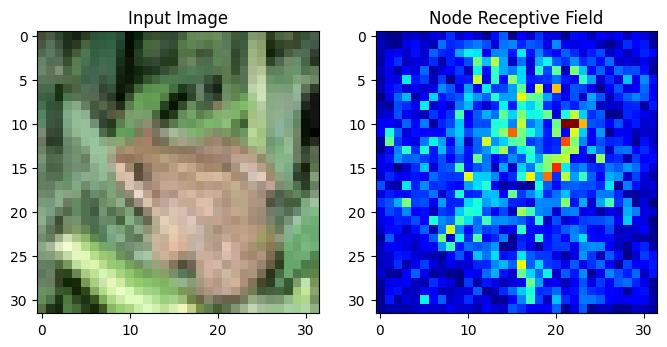


=== Running Double Descent Analysis ===
Epoch 5 | Train Acc: 87.04%
Epoch 10 | Train Acc: 91.96%
Epoch 15 | Train Acc: 94.76%
Epoch 20 | Train Acc: 97.70%
Epoch 25 | Train Acc: 98.08%
Epoch 30 | Train Acc: 97.67%
Capacity 2 -> Train Err: 0.0300 | Test Err: 0.1050
Epoch 5 | Train Acc: 89.25%
Epoch 10 | Train Acc: 93.27%
Epoch 15 | Train Acc: 96.14%
Epoch 20 | Train Acc: 98.02%
Epoch 25 | Train Acc: 99.11%
Epoch 30 | Train Acc: 99.79%
Capacity 4 -> Train Err: 0.0005 | Test Err: 0.0740
Epoch 5 | Train Acc: 89.16%
Epoch 10 | Train Acc: 93.16%
Epoch 15 | Train Acc: 96.75%
Epoch 20 | Train Acc: 97.42%
Epoch 25 | Train Acc: 97.59%
Epoch 30 | Train Acc: 98.51%
Capacity 8 -> Train Err: 0.0029 | Test Err: 0.0825
Epoch 5 | Train Acc: 90.12%
Epoch 10 | Train Acc: 93.34%
Epoch 15 | Train Acc: 96.24%
Epoch 20 | Train Acc: 97.58%
Epoch 25 | Train Acc: 99.01%
Epoch 30 | Train Acc: 98.88%
Capacity 16 -> Train Err: 0.0164 | Test Err: 0.0975
Epoch 5 | Train Acc: 89.66%
Epoch 10 | Train Acc: 93.89%
Epoch

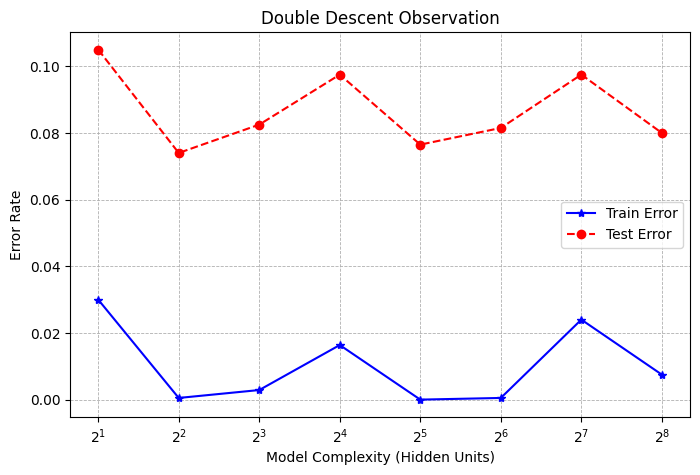

In [ ]:
# 1. Load CIFAR-10
train_ldr, val_ldr, test_ldr = get_dataloaders(dataset_name="cifar10")

# 2. Main Model Training
print("=== Training on CIFAR-10 ===")
main_trunk = CNNTrunk(feature_dim=64).to(device)
main_tree = TreeNeuralNetwork(trunk=main_trunk, feature_dim=64, depth=2, hidden_units=32).to(device)
train_to_interpolation(main_tree, train_ldr, val_ldr, max_epochs=150)

# 3. Visualizations & Double Descent
sample_img, _ = next(iter(test_ldr))
visualize_receptive_fields(main_tree, sample_img[0])
plot_double_descent(train_ldr, test_ldr)